# Notebook 15 — Kepler K-dwarf catalog analysis (DR25)

**Purpose:** build a reproducible, catalog-level description of Kepler KOIs around K-dwarf stars and clearly separate that from a true planet occurrence-rate measurement.

**Important scientific limitation:** the fraction of cataloged K-dwarf targets with a confirmed KOI is *not* an intrinsic planet occurrence rate. A defensible occurrence-rate analysis must account for transit geometry, pipeline detection completeness, catalog reliability/false positives, and the survey selection function. NASA publishes dedicated DR25 completeness and reliability products; this notebook does not pretend that a simple count corrects for them.

Definitions used here: K-dwarf temperature 3,900–5,200 K; illustrative planet-radius interval 1–4 Earth radii; period interval 1–100 days. These are analysis cuts, not universal definitions.

In [3]:
%pip -q install pandas numpy matplotlib requests

Note: you may need to restart the kernel to use updated packages.


In [4]:

import io
import time
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

TAP_SYNC = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
TAP_TABLES = "https://exoplanetarchive.ipac.caltech.edu/TAP/tables"
SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "StudentResearch-Exoplanet-Project/1.0"})

def tap_query(query, timeout=240):
    """Run an Exoplanet Archive TAP synchronous query and return a DataFrame."""
    response = SESSION.get(
        TAP_SYNC,
        params={"query": query, "format": "csv"},
        timeout=timeout
    )
    print("HTTP:", response.status_code, "| Content-Type:", response.headers.get("Content-Type"))
    response.raise_for_status()
    body = response.text.strip()
    if not body:
        raise RuntimeError("NASA TAP returned an empty response.")
    if body.startswith("<") or "QUERY_STATUS" in body[:500].upper():
        raise RuntimeError("NASA TAP returned XML/error text instead of CSV:\n" + body[:1200])
    try:
        frame = pd.read_csv(io.StringIO(body))
    except Exception as exc:
        raise RuntimeError("Could not parse NASA TAP CSV. First response text:\n" + body[:1200]) from exc
    if len(frame.columns) == 0:
        raise RuntimeError("NASA TAP response contained no columns.")
    frame.columns = [str(c).strip().lower() for c in frame.columns]
    return frame

def get_columns(table_name):
    """Try TAP_SCHEMA first, then fall back to SELECT TOP 1 *."""
    schema_query = (
        "SELECT column_name FROM TAP_SCHEMA.columns "
        f"WHERE table_name = '{table_name}'"
    )
    try:
        schema = tap_query(schema_query, timeout=120)
        cols = set(schema["column_name"].astype(str).str.lower())
        if cols:
            print(f"Found {len(cols)} columns through TAP_SCHEMA for {table_name}.")
            return cols
    except Exception as exc:
        print("TAP_SCHEMA lookup failed; trying direct table query:", str(exc)[:250])

    sample = tap_query(f"SELECT TOP 1 * FROM {table_name}", timeout=180)
    cols = set(sample.columns)
    if not cols:
        raise RuntimeError(f"Could not discover columns for {table_name}.")
    print(f"Found {len(cols)} columns through direct query for {table_name}.")
    return cols

def choose_columns(available, preferred, required=()):
    chosen = [c for c in preferred if c in available]
    missing = [c for c in required if c not in available]
    if missing:
        raise RuntimeError(f"Required columns missing: {missing}. Available columns include: {sorted(available)[:80]}")
    return chosen

def sql_select(table, columns, top=None):
    if not columns:
        raise ValueError(f"No columns selected for {table}")
    top_sql = f"TOP {int(top)} " if top else ""
    return f"SELECT {top_sql}{', '.join(columns)} FROM {table}"


## 1. Discover the available DR25 columns

In [5]:

KOI_TABLE = "q1_q17_dr25_koi"
STELLAR_TABLE = "q1_q17_dr25_ks"

koi_cols = get_columns(KOI_TABLE)
stellar_cols = get_columns(STELLAR_TABLE)

print("\nKOI columns:", sorted(koi_cols))
print("\nStellar columns:", sorted(stellar_cols))


HTTP: 200 | Content-Type: text/plain
HTTP: 200 | Content-Type: text/plain
Found 153 columns through direct query for q1_q17_dr25_koi.
HTTP: 200 | Content-Type: text/plain
HTTP: 200 | Content-Type: text/plain
Found 99 columns through direct query for q1_q17_dr25_ks.

KOI columns: ['dec', 'dec_err', 'dec_str', 'kepid', 'kepler_name', 'kepoi_name', 'koi_bin_oedp_sig', 'koi_comment', 'koi_count', 'koi_datalink_dvr', 'koi_datalink_dvs', 'koi_delivname', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_dicco_mdec', 'koi_dicco_mdec_err', 'koi_dicco_mra', 'koi_dicco_mra_err', 'koi_dicco_msky', 'koi_dicco_msky_err', 'koi_dikco_mdec', 'koi_dikco_mdec_err', 'koi_dikco_mra', 'koi_dikco_mra_err', 'koi_dikco_msky', 'koi_dikco_msky_err', 'koi_disp_prov', 'koi_disposition', 'koi_dor', 'koi_dor_err1', 'koi_dor_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_eccen', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_fittype', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_fpflag_nt', 'koi_fpfla

## 2. Retrieve only the columns needed for this analysis

In [6]:

koi_preferred = [
    "kepid", "kepoi_name", "koi_disposition", "koi_period",
    "koi_prad", "koi_duration", "koi_score"
]
stellar_preferred = ["kepid", "teff", "kic_teff", "radius", "logg"]

koi_selected = choose_columns(
    koi_cols, koi_preferred,
    required=("kepid", "koi_disposition", "koi_period", "koi_prad")
)
stellar_selected = choose_columns(
    stellar_cols, stellar_preferred,
    required=("kepid",)
)

koi = tap_query(sql_select(KOI_TABLE, koi_selected))
stars = tap_query(sql_select(STELLAR_TABLE, stellar_selected))

print("KOI rows:", len(koi), "| stellar target rows:", len(stars))
display(koi.head())
display(stars.head())


HTTP: 200 | Content-Type: text/plain
HTTP: 200 | Content-Type: text/plain
KOI rows: 8054 | stellar target rows: 200038


,kepid,kepoi_name,koi_disposition,koi_period,koi_prad,koi_duration,koi_score
0,10811496,K00753.01,FALSE POSITIVE,19.899140,14.60,1.78220,0.0
1,10848459,K00754.01,FALSE POSITIVE,1.736952,33.46,2.40641,0.0
2,10854555,K00755.01,CONFIRMED,2.525592,2.75,1.65450,1.0
3,10872983,K00756.01,CONFIRMED,11.094321,3.90,4.59450,1.0
4,10872983,K00756.02,CONFIRMED,4.134435,2.77,3.14020,1.0


,kepid,teff,radius,logg
0,10000785,5333,0.650,4.616
1,10000797,6289,1.195,4.270
2,10000800,5692,0.866,4.547
3,10000823,6580,1.169,4.377
4,10000827,5648,0.841,4.559


## 3. Identify K-dwarf targets and join catalog entries

In [7]:

# Prefer the DR25 stellar-table effective temperature. If it is unavailable,
# stop rather than silently substituting an unrelated temperature estimate.
temp_col = "teff" if "teff" in stars.columns else ("kic_teff" if "kic_teff" in stars.columns else None)
if temp_col is None:
    raise RuntimeError("No recognized effective-temperature column found in the DR25 stellar table.")

stars[temp_col] = pd.to_numeric(stars[temp_col], errors="coerce")
stars["kepid"] = pd.to_numeric(stars["kepid"], errors="coerce")
koi["kepid"] = pd.to_numeric(koi["kepid"], errors="coerce")

k_dwarfs = stars.loc[stars[temp_col].between(3900, 5200)].dropna(subset=["kepid"]).copy()
k_dwarfs["kepid"] = k_dwarfs["kepid"].astype("int64")

koi["koi_period"] = pd.to_numeric(koi["koi_period"], errors="coerce")
koi["koi_prad"] = pd.to_numeric(koi["koi_prad"], errors="coerce")

joined = koi.merge(
    k_dwarfs[["kepid", temp_col]].drop_duplicates("kepid"),
    on="kepid", how="inner", validate="many_to_one"
)
print("K-dwarf target stars:", k_dwarfs["kepid"].nunique())
print("KOI entries around K-dwarf targets:", len(joined))
display(joined.head())


K-dwarf target stars: 45159
KOI entries around K-dwarf targets: 1424


,kepid,kepoi_name,koi_disposition,koi_period,koi_prad,koi_duration,koi_score,teff
0,5456651,K00835.01,CONFIRMED,11.763072,2.35,2.90760,1.000,4959
1,8013419,K00901.01,CANDIDATE,12.732624,4.87,2.20830,1.000,3950
2,8018547,K00902.01,CANDIDATE,83.924940,4.78,6.79040,0.966,3960
3,8150320,K00904.01,CONFIRMED,2.211117,1.85,1.64850,1.000,4500
4,3233043,K00966.01,FALSE POSITIVE,0.379464,59.56,0.86896,0.000,5075


## 4. Apply the illustrative radius and period domain

In [8]:

in_domain = joined[
    joined["koi_prad"].between(1.0, 4.0) &
    joined["koi_period"].between(1.0, 100.0)
].copy()

confirmed = in_domain[
    in_domain["koi_disposition"].astype(str).str.upper().eq("CONFIRMED")
].copy()

false_positive = in_domain[
    in_domain["koi_disposition"].astype(str).str.upper().eq("FALSE POSITIVE")
].copy()

candidate = in_domain[
    in_domain["koi_disposition"].astype(str).str.upper().eq("CANDIDATE")
].copy()

summary = pd.DataFrame({
    "Quantity": [
        "K-dwarf target stars in DR25 stellar table",
        "KOI entries in chosen radius/period domain",
        "Confirmed entries in domain",
        "False-positive entries in domain",
        "Candidate entries in domain",
        "Unique K-dwarf hosts with confirmed entries in domain",
    ],
    "Value": [
        k_dwarfs["kepid"].nunique(),
        len(in_domain),
        len(confirmed),
        len(false_positive),
        len(candidate),
        confirmed["kepid"].nunique(),
    ]
})
display(summary)


,Quantity,Value
0,K-dwarf target stars in DR25 stellar table,45159
1,KOI entries in chosen radius/period domain,639
2,Confirmed entries in domain,463
3,False-positive entries in domain,85
4,Candidate entries in domain,91
5,Unique K-dwarf hosts with confirmed entries in...,322


## 5. Plot catalog distributions

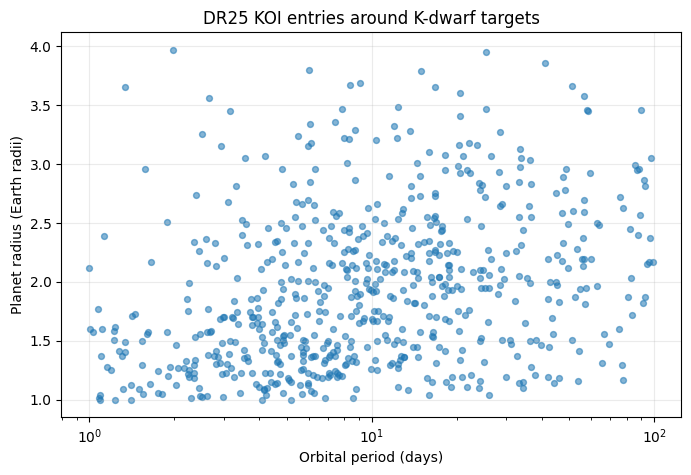

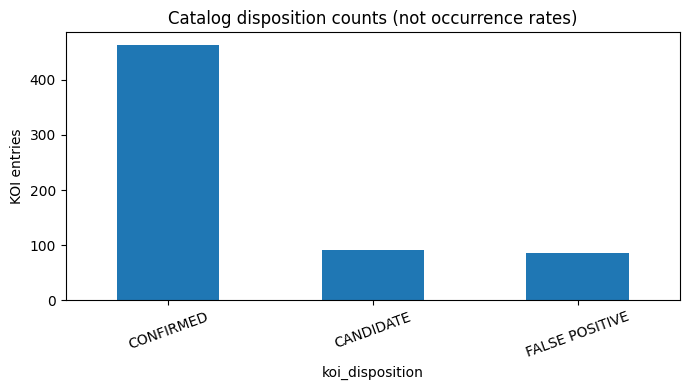

In [9]:

if len(in_domain):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(in_domain["koi_period"], in_domain["koi_prad"], s=18, alpha=0.55)
    ax.set_xscale("log")
    ax.set_xlabel("Orbital period (days)")
    ax.set_ylabel("Planet radius (Earth radii)")
    ax.set_title("DR25 KOI entries around K-dwarf targets")
    ax.grid(True, alpha=0.25)
    plt.show()

    disposition_counts = in_domain["koi_disposition"].astype(str).value_counts()
    disposition_counts.plot(kind="bar", figsize=(7, 4), rot=20)
    plt.ylabel("KOI entries")
    plt.title("Catalog disposition counts (not occurrence rates)")
    plt.tight_layout()
    plt.show()
else:
    print("No entries fell inside the chosen cuts; inspect the retrieved data and definitions.")


## 6. Export tables and state the scientific interpretation

In [10]:

joined.to_csv("DR25_K_dwarf_all_KOIs.csv", index=False)
in_domain.to_csv("DR25_K_dwarf_selected_domain.csv", index=False)
confirmed.to_csv("DR25_K_dwarf_confirmed_selected_domain.csv", index=False)
summary.to_csv("DR25_K_dwarf_summary.csv", index=False)

n_targets = k_dwarfs["kepid"].nunique()
n_hosts = confirmed["kepid"].nunique()
naive_fraction = n_hosts / n_targets if n_targets else np.nan

print(f"Naive catalog host fraction = {n_hosts}/{n_targets} = {naive_fraction:.4f}")
print("""
DO NOT report this number as the intrinsic occurrence rate.
It is only the fraction of DR25 K-dwarf target stars with at least one
catalog-confirmed KOI inside the chosen observed radius/period cuts.

A real occurrence-rate estimate needs, at minimum:
1. per-target detection completeness across the chosen period/radius domain;
2. transit-probability correction (geometry and stellar/planet parameters);
3. reliability / false-positive correction for detected candidates;
4. treatment of multiple planets per system and survey selection effects;
5. uncertainty propagation and a documented, validated estimator.

NASA DR25 documentation describes per-target completeness products and
reliability products. Use the published DR25 products and the associated
methodology before making any intrinsic occurrence-rate claim.
""")


Naive catalog host fraction = 322/45159 = 0.0071

DO NOT report this number as the intrinsic occurrence rate.
It is only the fraction of DR25 K-dwarf target stars with at least one
catalog-confirmed KOI inside the chosen observed radius/period cuts.

A real occurrence-rate estimate needs, at minimum:
1. per-target detection completeness across the chosen period/radius domain;
2. transit-probability correction (geometry and stellar/planet parameters);
3. reliability / false-positive correction for detected candidates;
4. treatment of multiple planets per system and survey selection effects;
5. uncertainty propagation and a documented, validated estimator.

NASA DR25 documentation describes per-target completeness products and
reliability products. Use the published DR25 products and the associated
methodology before making any intrinsic occurrence-rate claim.

